# Managing overlap with weights and sequential sampling

The released rule increases a multiplier from an old-data level toward one as cumulative event weight moves forward:

$$
Q_i=\sum_{j=1}^{i}q_j,\qquad
d_i(c)=c+(1-c)\frac{Q_i}{Q_n},\qquad 0\leq c\leq1.
$$

Here, $q_j\geq0$ is the input weight of ordered event $j$; $Q_i$ is cumulative weight through event $i$; $Q_n$ is total weight. $c\in[0,1]$ is the chosen old-data level; $d_i(c)$ is the multiplier for event $i$; $d_n(c)=1.$

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
import sys
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from IPython.display import Image
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
DATA_URL = 'https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2021-01.zip'
DATA_DIR = ROOT / 'data' / 'public' / 'binance'
DATA_PATH = ensure_dataset(ROOT, 'binance_btcusdt')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
public_columns = ['Open time', 'Open', 'High', 'Low', 'Close', 'Volume', 'Close time', 'Quote volume', 'Trades', 'Buyer base volume', 'Buyer quote volume', 'Unused']
raw = pd.read_csv(DATA_PATH, compression='zip', header=None, names=public_columns, nrows=None)
raw['time'] = pd.to_datetime(raw['Open time'], unit='ms', utc=True).dt.tz_convert(None)
raw = raw.rename(columns={'Close': 'close', 'Volume': 'volume', 'Quote volume': 'quote_volume', 'Trades': 'trades'})
raw = raw.sort_values('time').drop_duplicates('time').reset_index(drop=True)
from RiskLabAI.data.labeling import cusum_filter_events_dynamic_threshold, daily_volatility_with_log_returns, vertical_barrier
from RiskLabAI.data.weights import calculate_average_uniqueness, calculate_time_decay, expand_label_for_meta_labeling, sample_weight_absolute_return_meta_labeling
FIGURES = ROOT / 'outputs' / 'figures' / '07_overlapping_information_weights'
TABLES = ROOT / 'outputs' / 'tables' / '07_overlapping_information_weights'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True):
    frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position='H'))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')
raw = raw.sort_values('time').dropna(subset=['time', 'close']).drop_duplicates('time').reset_index(drop=True)
minute_close = pd.Series(raw['close'].to_numpy(dtype=float), index=pd.DatetimeIndex(raw['time']), name='One-minute close')
close = minute_close.resample('15min').last().dropna().rename('Fifteen-minute close')
log_price = np.log(close)
volatility = daily_volatility_with_log_returns(close, span=100)
event_times = cusum_filter_events_dynamic_threshold(log_price, volatility.dropna())
event_ends = vertical_barrier(close, event_times, number_days=1)
event_times = event_times.intersection(event_ends.index).intersection(volatility.dropna().index)
event_ends = event_ends.loc[event_times]

def build_indicator_matrix(index, ends):
    matrix = pd.DataFrame(0, index=index, columns=ends.index, dtype=np.int8)
    for start, end in ends.items():
        matrix.loc[start:end, start] = 1
    return matrix
indicator_matrix = build_indicator_matrix(close.index, event_ends)
event_duration = indicator_matrix.sum(axis=0).astype(int)
matrix_concurrency = indicator_matrix.sum(axis=1).astype(int)
active_concurrency = matrix_concurrency[matrix_concurrency > 0]
library_concurrency = expand_label_for_meta_labeling(close.index, event_ends, event_times).astype(int)
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


## Decay Along Cumulative Information

,Old-data level,Oldest observed factor,Newest factor,Effective sample size,Largest ten weights' share
0,1,1,1,104.505456,0.170115
1,0.5,0.503807,1,101.543506,0.183161
2,0,0.007615,1,79.419193,0.236630


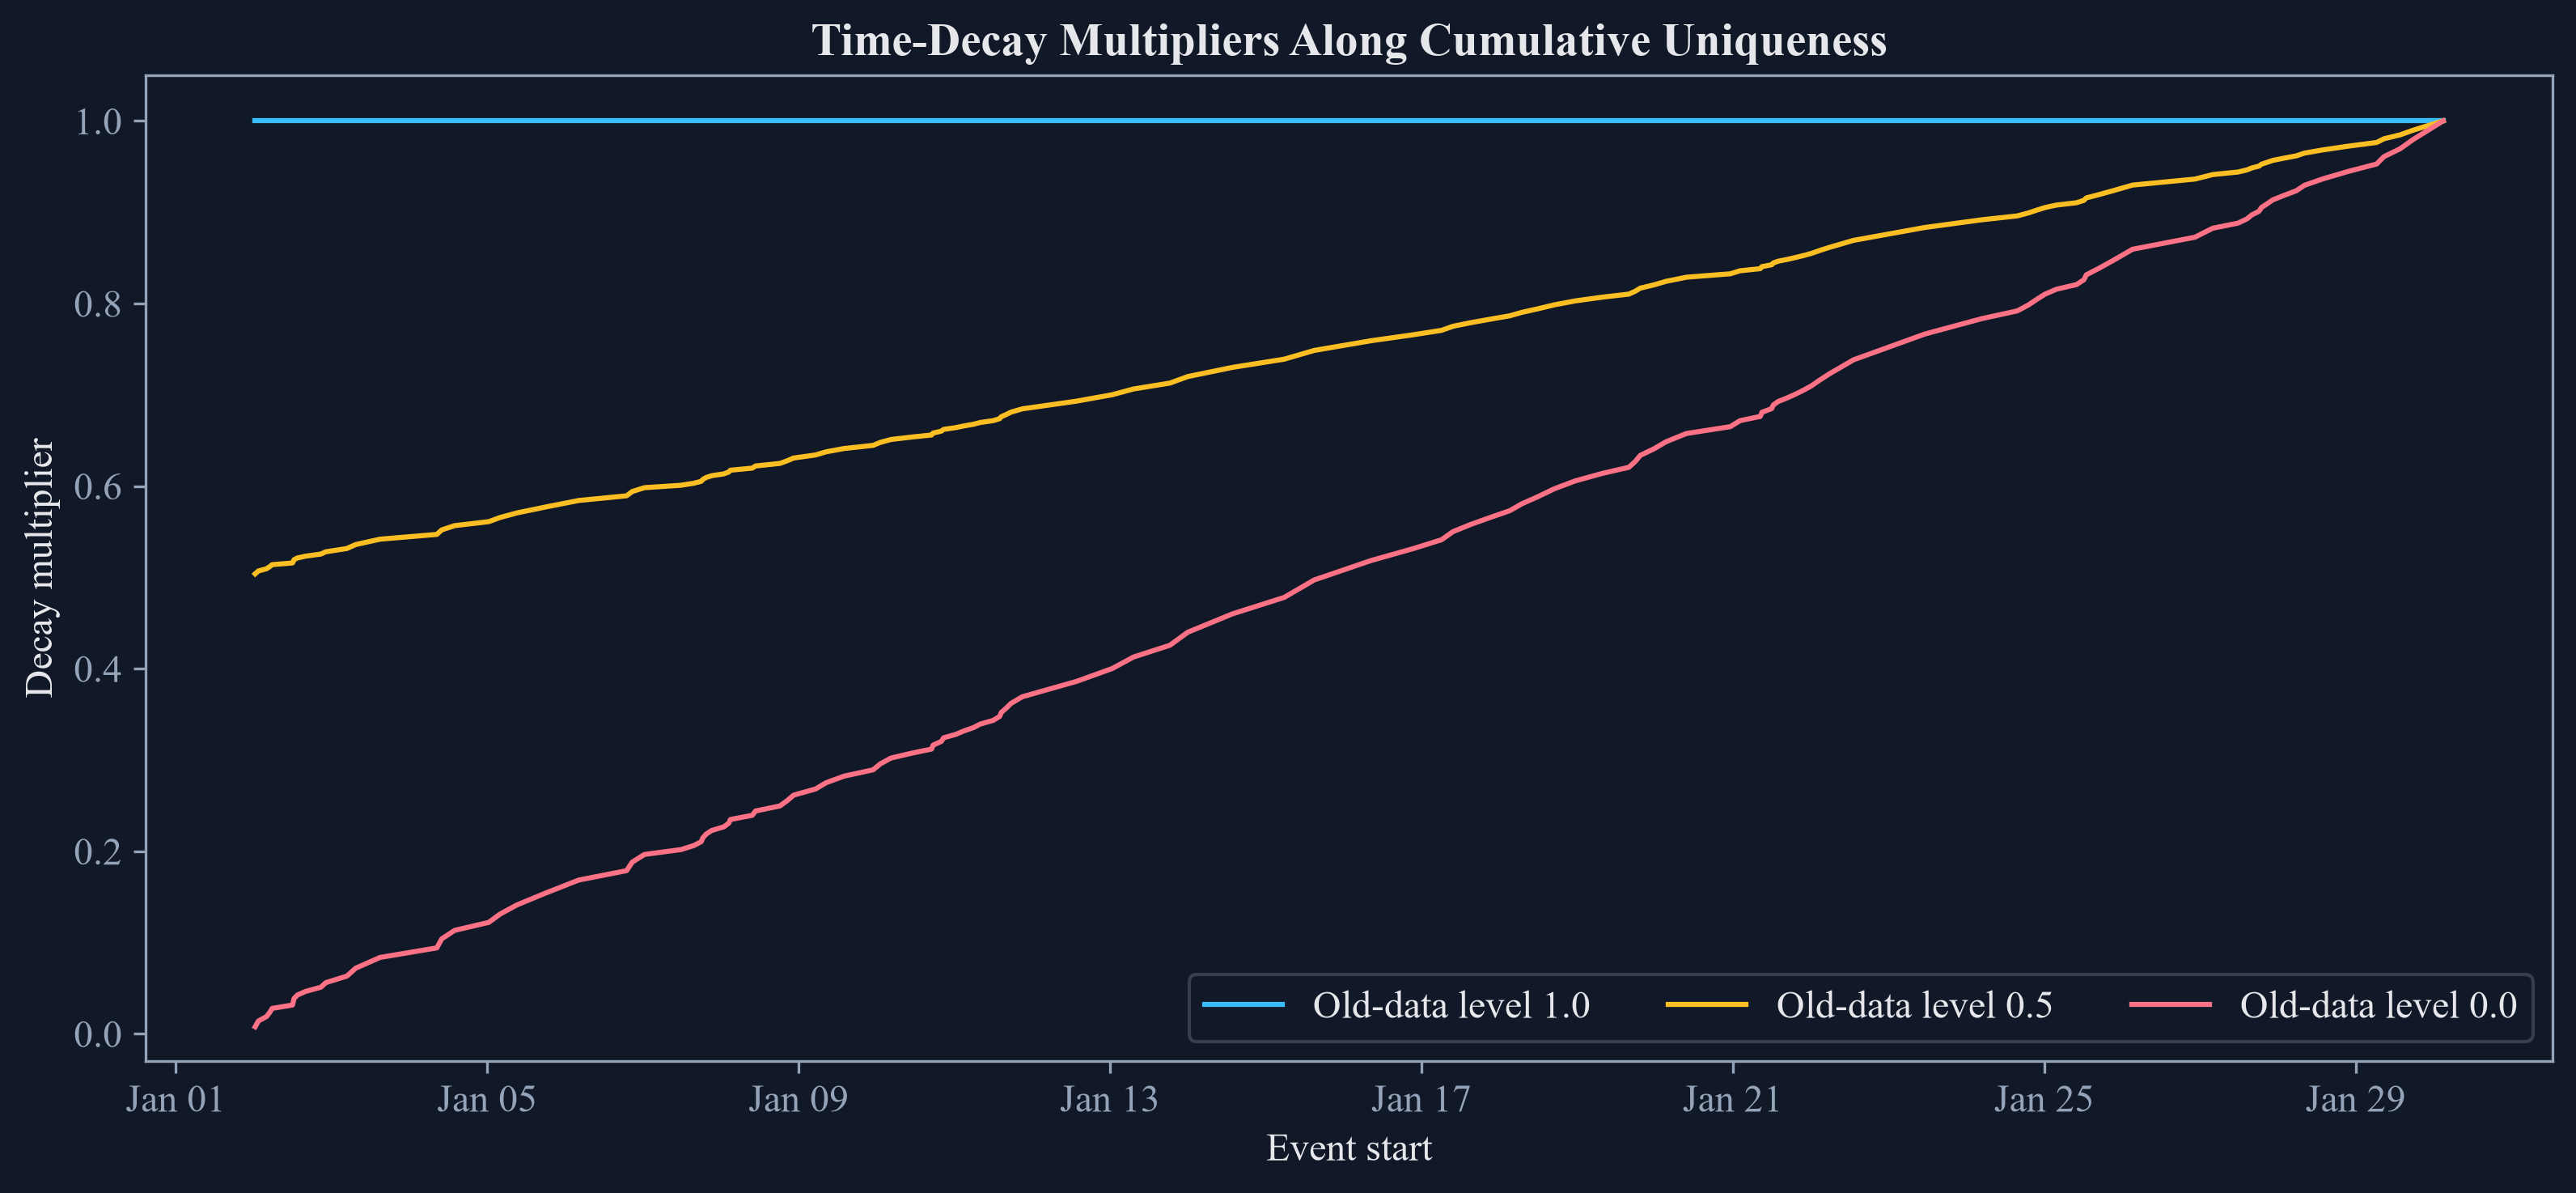

In [2]:
average_uniqueness = calculate_average_uniqueness(indicator_matrix)
attribution_weights = sample_weight_absolute_return_meta_labeling(event_ends, close, event_times)

def effective_sample_size(weight):
    values = np.asarray(weight, dtype=float)
    return float(values.sum() ** 2 / np.square(values).sum())

decay_levels = [1.0, 0.5, 0.0]
decay_factors = {level: calculate_time_decay(average_uniqueness, clf_last_weight=level) for level in decay_levels}
final_weights = {level: attribution_weights * decay_factors[level] for level in decay_levels}
time_decay_summary = pd.DataFrame({
    "Old-data level": decay_levels,
    "Oldest observed factor": [decay_factors[level].iloc[0] for level in decay_levels],
    "Newest factor": [decay_factors[level].iloc[-1] for level in decay_levels],
    "Effective sample size": [effective_sample_size(final_weights[level]) for level in decay_levels],
    "Largest ten weights' share": [pd.Series(final_weights[level]).nlargest(10).sum() / pd.Series(final_weights[level]).sum() for level in decay_levels],
})
save_table(time_decay_summary, "time_decay_summary", "Time-decay factors and effective sample sizes for the public event sample.", "tab:chapter6-time-decay", fit=True)
display(time_decay_summary.round(6))

figure, axis = plt.subplots(figsize=(10.5, 4.8), constrained_layout=True)
colors = {1.0: palette["cyan"], 0.5: palette["amber"], 0.0: palette["rose"]}
for level in decay_levels:
    axis.plot(event_times, decay_factors[level], color=colors[level], linewidth=1.5, label=f"Old-data level {level:.1f}")
axis.set_title("Time-Decay Multipliers Along Cumulative Uniqueness")
axis.set_xlabel("Event start")
axis.set_ylabel("Decay multiplier")
axis.set_ylim(-0.03, 1.05)
axis.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
axis.legend(ncol=3)
figure.savefig(FIGURES / "time_decay_factors.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "time_decay_factors.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "time_decay_factors.png")))
plt.close(figure)

## Sequential Sampling

Before draw $k,$ every candidate is scored by the uniqueness it would add, and its score becomes its draw probability:

$$
\overline u_j^{(k)}=\frac{1}{L_j}\sum_t\frac{I_{tj}}{c_t^{(k-1)}+I_{tj}},\qquad
p_j^{(k)}=\frac{\overline u_j^{(k)}}{\sum_{\ell=1}^{n}\overline u_\ell^{(k)}}.
$$

Here, $k$ is the draw number; $j$ and $\ell$ label candidate events; $L_j$ is candidate $j$'s length. $c_t^{(k-1)}$ is concurrency from earlier draws; $I_{tj}$ is candidate activity; $\overline u_j^{(k)}$ is added uniqueness; $p_j^{(k)}$ is draw probability.

,Method,Mean uniqueness,10th percentile,Middle value,90th percentile,Paired wins
0,Ordinary sampling with replacement,0.203242,0.195551,0.203628,0.211208,0
1,Sequential uniqueness sampling,0.213922,0.210984,0.214712,0.216495,80


,Group,Ordinary share,Sequential share,Sequential minus ordinary
0,Lowest uniqueness,0.257989,0.199812,-0.058177
1,Lower middle,0.242857,0.216917,-0.025940
2,Upper middle,0.252162,0.260808,0.008647
3,Highest uniqueness,0.246992,0.322462,0.075470


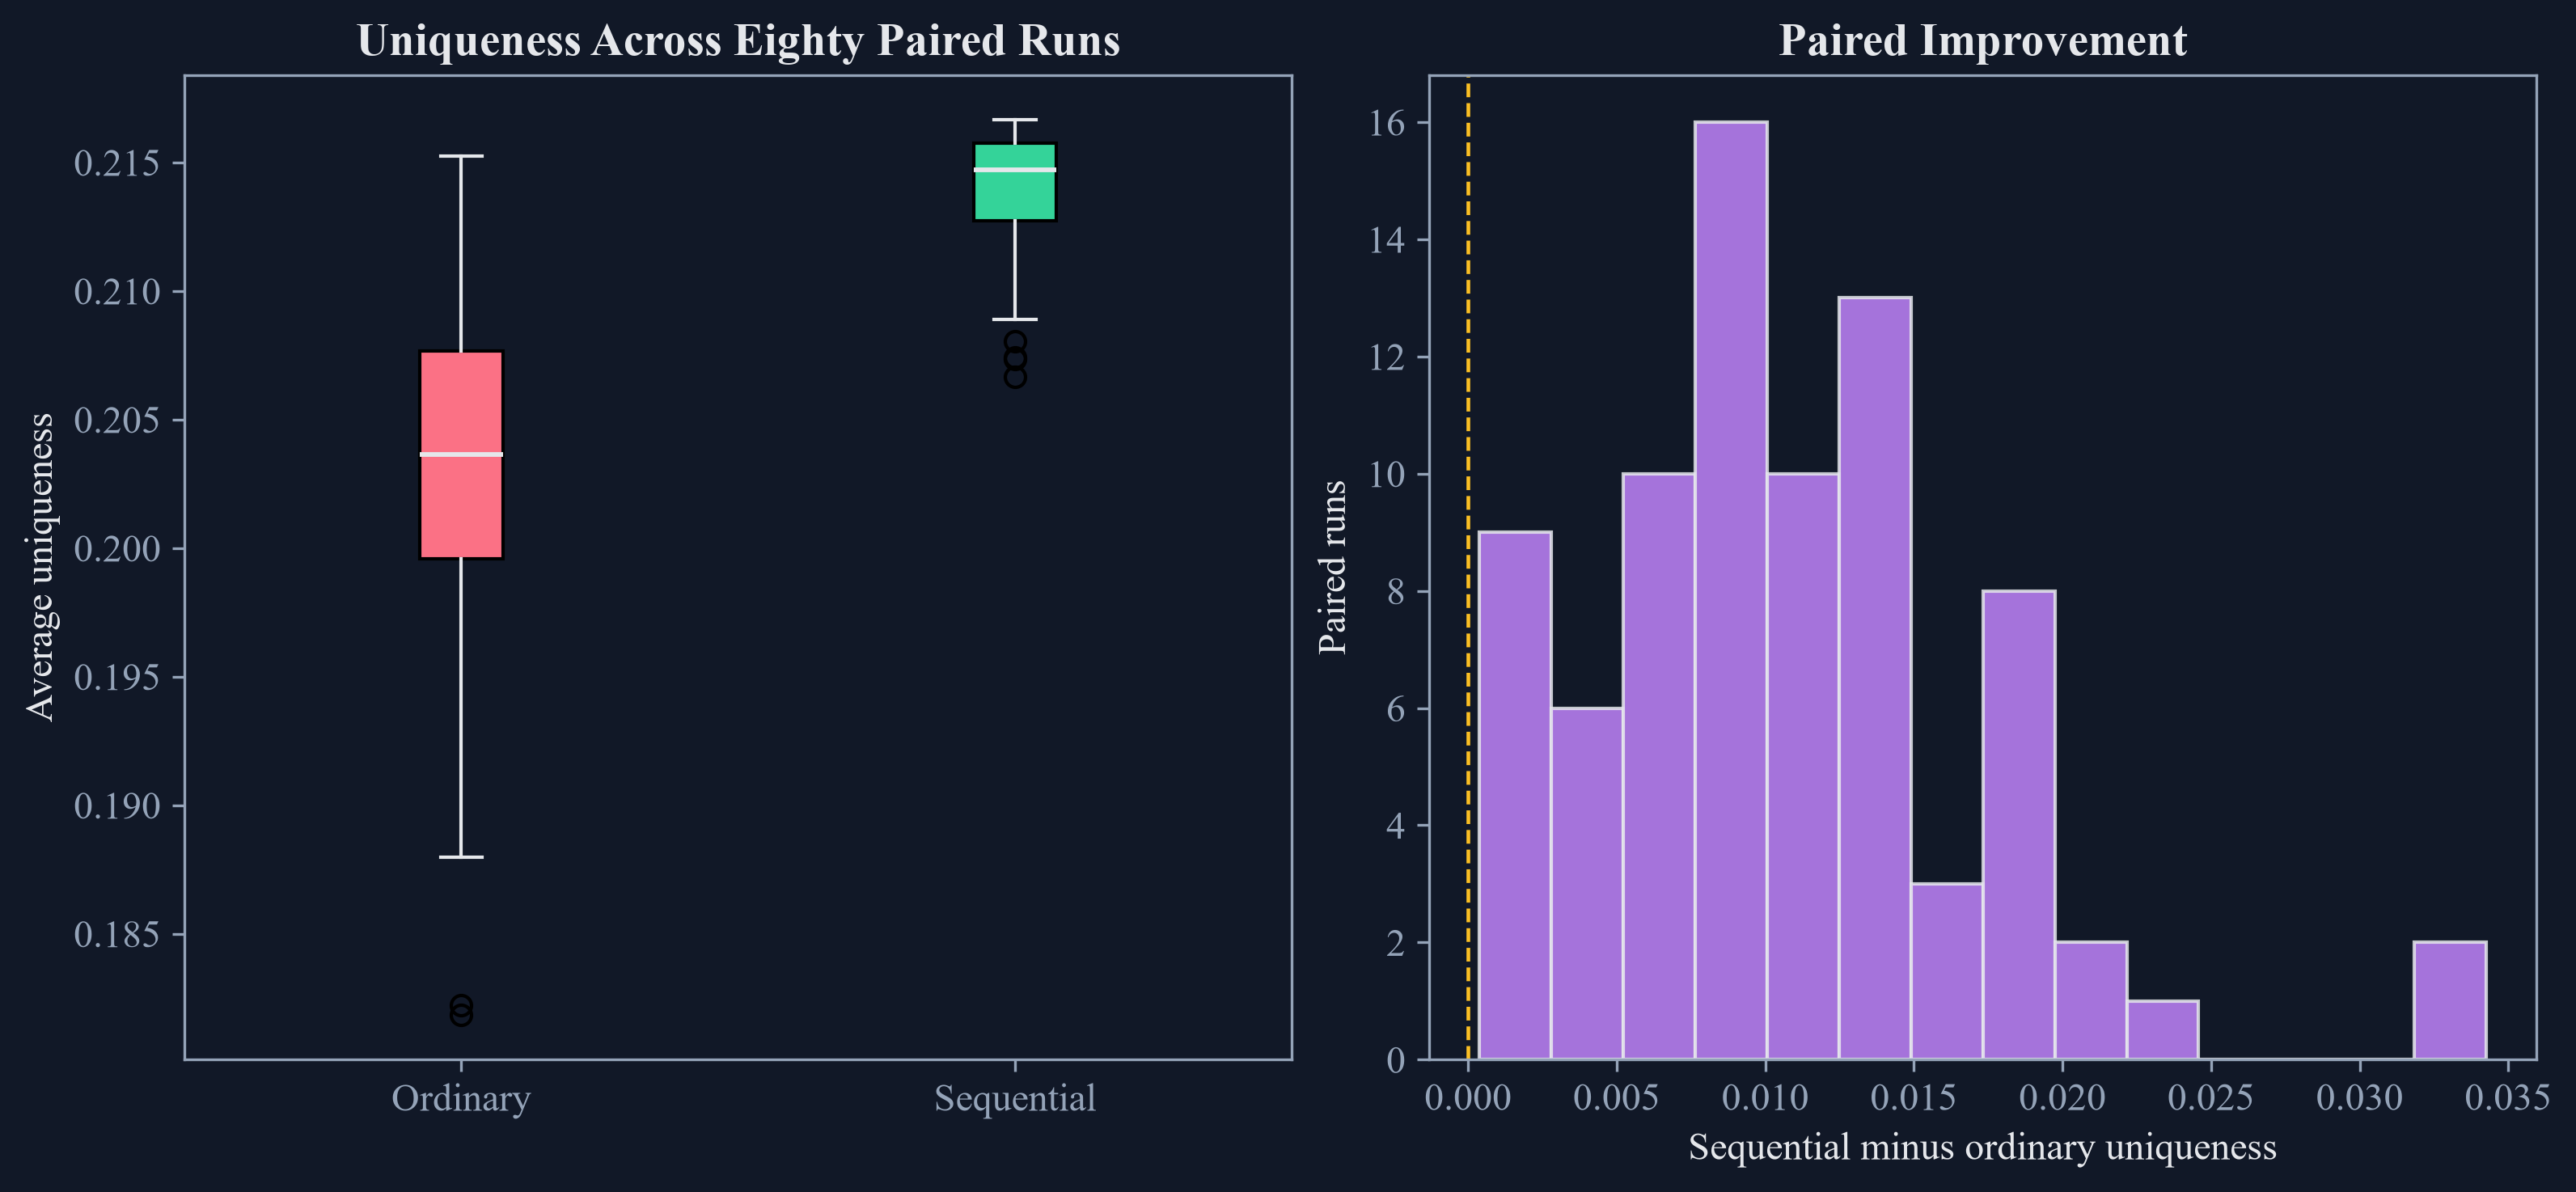

In [3]:
indicator_array = indicator_matrix.to_numpy(dtype=np.int8)
start_positions = np.array([close.index.get_loc(start) for start in event_times], dtype=int)
end_positions = np.array([close.index.get_loc(event_ends.loc[start]) for start in event_times], dtype=int)

def sample_average_uniqueness(draw):
    selected = indicator_array[:, draw].astype(float)
    concurrency = selected.sum(axis=1)
    uniqueness = np.divide(selected, concurrency[:, None], out=np.zeros_like(selected), where=concurrency[:, None] > 0)
    return float(np.mean(uniqueness.sum(axis=0) / selected.sum(axis=0)))

def sequential_sample(generator, sample_length):
    concurrency = np.zeros(indicator_array.shape[0], dtype=float)
    draw = []
    for _ in range(sample_length):
        scores = np.array([np.mean(1.0 / (concurrency[left:right + 1] + 1.0)) for left, right in zip(start_positions, end_positions)])
        chosen = int(generator.choice(indicator_array.shape[1], p=scores / scores.sum()))
        draw.append(chosen)
        concurrency[start_positions[chosen]:end_positions[chosen] + 1] += 1.0
    return np.asarray(draw, dtype=int)

generator = np.random.default_rng(20260926)
repetitions = 80
ordinary_draws = []
sequential_draws = []
ordinary_uniqueness = []
sequential_uniqueness = []
for _ in range(repetitions):
    ordinary_draw = generator.choice(len(event_times), size=len(event_times), replace=True)
    sequential_draw = sequential_sample(generator, len(event_times))
    ordinary_draws.append(ordinary_draw)
    sequential_draws.append(sequential_draw)
    ordinary_uniqueness.append(sample_average_uniqueness(ordinary_draw))
    sequential_uniqueness.append(sample_average_uniqueness(sequential_draw))
ordinary_draws = np.vstack(ordinary_draws)
sequential_draws = np.vstack(sequential_draws)
ordinary_uniqueness = np.asarray(ordinary_uniqueness)
sequential_uniqueness = np.asarray(sequential_uniqueness)
paired_difference = sequential_uniqueness - ordinary_uniqueness
sampling_summary = pd.DataFrame({
    "Method": ["Ordinary sampling with replacement", "Sequential uniqueness sampling"],
    "Mean uniqueness": [ordinary_uniqueness.mean(), sequential_uniqueness.mean()],
    "10th percentile": [np.quantile(ordinary_uniqueness, 0.10), np.quantile(sequential_uniqueness, 0.10)],
    "Middle value": [np.median(ordinary_uniqueness), np.median(sequential_uniqueness)],
    "90th percentile": [np.quantile(ordinary_uniqueness, 0.90), np.quantile(sequential_uniqueness, 0.90)],
    "Paired wins": [int((ordinary_uniqueness > sequential_uniqueness).sum()), int((sequential_uniqueness > ordinary_uniqueness).sum())],
})

uniqueness_group = pd.qcut(average_uniqueness, 4, labels=["Lowest uniqueness", "Lower middle", "Upper middle", "Highest uniqueness"])
ordinary_frequency = np.bincount(ordinary_draws.ravel(), minlength=len(event_times)) / ordinary_draws.size
sequential_frequency = np.bincount(sequential_draws.ravel(), minlength=len(event_times)) / sequential_draws.size
frequency_frame = pd.DataFrame({"Group": uniqueness_group, "Ordinary share": ordinary_frequency, "Sequential share": sequential_frequency})
selection_frequency_summary = frequency_frame.groupby("Group", sort=True, observed=True)[["Ordinary share", "Sequential share"]].sum().reset_index()
selection_frequency_summary["Sequential minus ordinary"] = selection_frequency_summary["Sequential share"] - selection_frequency_summary["Ordinary share"]
save_table(sampling_summary, "sampling_summary", "Average uniqueness under ordinary and sequential sampling with replacement.", "tab:chapter6-sampling-summary", fit=True)
save_table(selection_frequency_summary, "selection_frequency_summary", "Selection shares by original-event uniqueness group.", "tab:chapter6-selection-frequency", fit=True)
display(sampling_summary.round(6))
display(selection_frequency_summary.round(6))

figure, axes = plt.subplots(1, 2, figsize=(10.5, 4.8), constrained_layout=True)
box = axes[0].boxplot([ordinary_uniqueness, sequential_uniqueness], tick_labels=["Ordinary", "Sequential"], patch_artist=True, medianprops={"color": palette["text"], "linewidth": 1.4})
box["boxes"][0].set_facecolor(palette["rose"])
box["boxes"][1].set_facecolor(palette["green"])
for element in ["whiskers", "caps"]:
    for artist in box[element]:
        artist.set_color(palette["text"])
axes[0].set_ylabel("Average uniqueness")
axes[0].set_title("Uniqueness Across Eighty Paired Runs")
axes[1].hist(paired_difference, bins=14, color=palette["violet"], alpha=0.85, edgecolor=palette["text"])
axes[1].axvline(0.0, color=palette["amber"], linestyle="--", linewidth=1.1)
axes[1].set_xlabel("Sequential minus ordinary uniqueness")
axes[1].set_ylabel("Paired runs")
axes[1].set_title("Paired Improvement")
figure.savefig(FIGURES / "sampling_comparison.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "sampling_comparison.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "sampling_comparison.png")))
plt.close(figure)

## Effective Sample Size

Effective sample size converts unequal nonnegative weights into the size of an equally weighted sample with the same concentration:

$$
n_{\mathrm{eff}}(a)=\frac{\left(\sum_{i=1}^{n}a_i\right)^2}{\sum_{i=1}^{n}a_i^2},\qquad
1\leq n_{\mathrm{eff}}(a)\leq n.
$$

Here, $a_i\geq0$ is event $i$'s final weight; $n$ is the number of positive-weight events. $n_{\mathrm{eff}}(a)$ is effective sample size; the upper bound occurs for equal weights and the lower bound for one concentrated weight.

In [4]:
effective_sample_summary = pd.DataFrame({
    "Weight rule": ["Equal event weights", "Attribution weights", "Attribution with old-data level 0.5", "Attribution with old-data level 0.0"],
    "Effective sample size": [effective_sample_size(np.ones(len(event_times))), effective_sample_size(attribution_weights), effective_sample_size(final_weights[0.5]), effective_sample_size(final_weights[0.0])],
    "Share of 133 events": [effective_sample_size(np.ones(len(event_times))) / len(event_times), effective_sample_size(attribution_weights) / len(event_times), effective_sample_size(final_weights[0.5]) / len(event_times), effective_sample_size(final_weights[0.0]) / len(event_times)],
})
save_table(effective_sample_summary, "effective_sample_size", "Effective sample size under four event-weight rules.", "tab:chapter6-effective-sample-size", fit=True)
display(effective_sample_summary.round(6))

,Weight rule,Effective sample size,Share of 133 events
0,Equal event weights,133,1
1,Attribution weights,104.505456,0.785755
2,Attribution with old-data level 0.5,101.543506,0.763485
3,Attribution with old-data level 0,79.419193,0.597137


## Tests

In [5]:
total_uniqueness = average_uniqueness.sort_index().cumsum()
for level in decay_levels:
    expected = level + (1.0 - level) * total_uniqueness / total_uniqueness.iloc[-1]
    assert np.allclose(decay_factors[level], expected)
    assert np.isclose(decay_factors[level].iloc[-1], 1.0)
    assert decay_factors[level].is_monotonic_increasing
invalid_raised = False
try:
    calculate_time_decay(average_uniqueness, clf_last_weight=-0.1)
except ValueError:
    invalid_raised = True
assert invalid_raised
assert repetitions == 80
assert ordinary_draws.shape == (80, 133)
assert sequential_draws.shape == (80, 133)
assert sequential_uniqueness.mean() > ordinary_uniqueness.mean()
assert (paired_difference > 0.0).mean() >= 0.95
assert np.isclose(selection_frequency_summary['Ordinary share'].sum(), 1.0)
assert np.isclose(selection_frequency_summary['Sequential share'].sum(), 1.0)
assert selection_frequency_summary.iloc[-1]['Sequential minus ordinary'] > 0.0
assert np.isclose(effective_sample_size(np.ones(len(event_times))), len(event_times))
assert all((1.0 <= effective_sample_size(final_weights[level]) <= len(event_times) for level in decay_levels))
assert effective_sample_size(final_weights[0.0]) < effective_sample_size(final_weights[1.0])
assert np.all(np.isfinite(ordinary_uniqueness))
assert np.all(np.isfinite(sequential_uniqueness))
